# The N-module power-shuffler string: derivation, equilibrium, controllability, switching twin, and how we got here

**Purpose.** This notebook consolidates every analytical step of the project into one derivation of the $N$-module
string of interleaved buck-boost power shufflers, re-applies the techniques of the earlier notebooks
(`shuffler_statespace`, `shuffler_integrated`, `shuffler_retrospective`) to it, and checks the result against the
identified plants (Simulink averaged model, QSPICE switching model at 200 / 300 / 400 kHz) and against a switching-level
twin. The code lives in `nstring.py` (numeric), `nstring_derive.py` (symbolic, sympy) and `nswitch.py` (switching);
the QSPICE experiments behind section 9 are in `data/` (`qspice_ud_sweep.py`, `qspice_ideal_switch.py`).

| section | question it answers |
|---|---|
| 0 | How we got here: which parts of the earlier analysis survived, and the one mis-diagnosis |
| 1 | Topology, drawing, variable list |
| 2 | Switch states: the 9 valid states, the 4 we average over, what dead time does |
| 3 | KVL / KCL of one shuffler and the module ladder, the averaged $N$-module model |
| 4 | Equilibrium: duty = voltage ratio, the tridiagonal charge balance $T\,i_m = \Delta I$, $I_{str} = \overline{I}$ |
| 5 | Small signal: $G(N)$ in closed form, the identified gain sets |
| 6 | Controllability and observability for $N$ modules |
| 7 | Modes and phase portraits with the real damping |
| 8 | The switching twin: ripple, coupling sense, dead time, and the origin of the "switching resistance" |
| 9 | Closed loop with the deployed PI + decoupler |
| 10 | How far off, the formulas to keep, open items |

## 0 · How we got here

The story as it stands in the design log and the retrospective, checked against the notebooks:

| stage | what was done | notebook / file | verdict today |
|---|---|---|---|
| progress report, App. B | averaged model of one shuffler with two **independent** inductors; 4 dual-switch states out of the 9 valid ones (the rest are dead-time / freewheel states); state $x=[I_{L1},I_{L2},V_{C1},V_{C2}]$, control $[d_A,d_B]$, exogenous $[I_{pv1},I_{pv2},I_{load}]$; equilibrium $D_A=D_B=D$, $V_{C2}/V_{C1}=D/(1-D)$; marginally stable ($0,0,\pm j\omega_0$); common / differential modes; controllable iff $\bar I\neq0$, $V_\Sigma\neq0$, duty not saturated; observable only with per-phase current sensing; three decoupled SISO PI loops | `shuffler_statespace.ipynb` §1-§12 | state / input vectors and the equilibrium **hold** for the $N$-module string (§4); the modal split is the **right physics** (§0.1); "marginal stability" was an artefact of $R\to0$ |
| ideal string studies | behavioural string + P&O + partial shading, energy returns; nested PI "equaliser" | `shuffler_sim.ipynb` | unchanged, not part of the dynamics story |
| coupled inductor | ERUC23 T-model, $L_{self}=7.9$ µH, $M=5.85$ µH: resonance moves off the axis, damped by winding $R$ | `shuffler_statespace.ipynb` §6, `shuffler_integrated.ipynb` §2 | correct, but the mode assignment ($L+M$ to the sum mode) is the **opposite** of the as-built circuit (§8.1) |
| MIMO LQR + integral servo | 4-state plant pinned by the module conductance $g$, tracked $y=[V_{C1}-V_{C2},\,I_{L1}-I_{L2}]$, `dlqr` at 200 kHz | `shuffler_integrated.ipynb` §10-§12, `matlab/shuffler_mimo_design.m` | the tracked pair is **exactly** the pair the final firmware controls ($v_d$ and the circulating current); it failed in Simulink for two reasons found later: the sensed $I_{LA}+I_{LB}$ *is* the circulating current (naming swap, §0.1) and the ideal averaged model had no damping (decision 3.2) |
| retrospective | identification disagrees "in kind"; corrected "current mode / voltage mode" model | `shuffler_retrospective.ipynb` | the corrected equations are the **same equations** as App. B written in the sensed coordinates: a relabelling, not a new topology (§0.1); the resonance fit used $C/2$ and $L+M$, both wrong (§7, §8.1) |
| 4-module string, decoupler | $u = G^{-1}\mathrm{diag}(k_I)\int e$, identified $G$, 61 mΩ damping | `4_Simulink`, decisions 3.1-3.6 | the structure $G(N)$ is derived here in closed form (§5) and the 61 mΩ is explained (§8.4) |
| this notebook | $N$-module ladder + sum / difference winding modes; switching twin | `nstring.py`, `nstring_derive.py`, `nswitch.py` | — |

So the user's account is right in every step but one: the model was **not** "wrong in kind". Both the LQR failure and the
retrospective's diagnosis trace to the *orientation of one current sensor* and to a *damping resistance* thirty times too
small, not to a mis-transcribed power path. The next cell shows it with numbers.

In [1]:
import math, json, os, sys, time
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import nstring as ns, nstring_derive as nd, nswitch as sw
np.set_printoptions(precision=3, suppress=True, linewidth=150)
sys.path.insert(0, os.path.join(ns.REPO, '8_Results', 'analysis'))
import stepmetrics as sm
DATA = os.path.join(os.path.dirname(os.path.abspath('nstring.py')), 'data')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('modules loaded; data files:', sorted(os.listdir(DATA)))

modules loaded; data files: ['nswitch_static.json', 'qspice_ideal_switch.json', 'qspice_ideal_switch.log', 'qspice_ud_sweep.json', 'qspice_ud_sweep.log', 'qspice_ud_sweep.npz', 'work_ideal_switch', 'work_ud_sweep']


### 0.1 · The 2026 model and the measurement are the same physics in two coordinate systems

App. B defines both inductor currents from the midpoint towards the switch node, so $I_{L1}-I_{L2}$ is the loop current that
circulates pole-to-pole and $I_{L1}+I_{L2}$ is the current injected at the midpoint. The build senses $I_{LA}$ and $I_{LB}$
with the B winding read the other way (`shuffler_recon.h`: "iB = -ILB"), so the sensed sum $I_{LA}+I_{LB}$ **is** the
circulating current and the sensed difference is the injected current. Evaluate App. B's DC gains, relabel, and compare
with the 2-module identification of 2026-06-27 (with the battery path resistance 0.386 Ω that identification saw):

In [2]:
o = nd.original_2026_model()
IL1, IL2, VC1, VC2, C1, C2, Ipv1, Ipv2, Iload = o['syms']
L_SELF, L_M, R_W, C_CAP, VMOD, G_MOD = 7.9e-6, 5.85e-6, 1.85e-3, 100e-6, 38.7, 0.368
def original_dc(Rw):
    # App. B averaged model, independent inductors, pinned by g (shuffler_integrated section 10), numeric at d = 0.5
    Linv = np.linalg.inv([[L_SELF, L_M], [L_M, L_SELF]])
    A = np.zeros((4, 4)); B = np.zeros((4, 2))
    A[:2, :] = Linv @ (np.array([[0, 0, -0.5, 0.5], [0, 0, -0.5, 0.5]]) - Rw * np.array([[1., 0, 0, 0], [0, 1, 0, 0]]))
    B[:2, :] = Linv @ np.array([[-2 * VMOD, 0], [0, -2 * VMOD]])
    A[2, :] = [0.5 / C_CAP, 0.5 / C_CAP, 0, 0]; A[3, :] = [-0.5 / C_CAP, -0.5 / C_CAP, 0, 0]
    B[2, :] = [6.0 / C_CAP] * 2; B[3, :] = [6.0 / C_CAP] * 2
    A[2, 2] -= G_MOD / C_CAP; A[3, 3] -= G_MOD / C_CAP
    Cm = np.array([[0, 0, 1, -1.], [1, -1, 0, 0], [1, 1, 0, 0], [0, 0, 1, 1]])     # vd, IL1-IL2 (circulating), IL1+IL2 (injected), vc
    Tm = np.array([[0.5, 0.5], [0.5, -0.5]])                                       # [dA; dB] = Tm [uc; ud]
    return -Cm @ np.linalg.inv(A) @ B @ Tm
meas = np.array([[-76.5, -0.36], [3.5, -200.4], [-32.2, -0.05], [-1.8, -0.09]])     # measured rows: v_diff, ILA+ILB, ILA-ILB, v_comm
G_orig = original_dc(R_W); G_batt = original_dc(2 * VMOD / 200.4)
print(f"{'row':34s} {'App.B, R=1.85 mOhm':>20s} {'App.B, R=0.386 ohm':>20s} {'measured 2026-06-27':>20s}")
for name, r in (('v_d  / [u_c, u_d]', 0), ('circulating (ILA+ILB) / [u_c, u_d]', 1), ('injected (ILA-ILB) / [u_c, u_d]', 2), ('v_c  / [u_c, u_d]', 3)):
    print(f"{name:34s} {G_orig[r,0]:9.1f} {G_orig[r,1]:9.1f}  {G_batt[r,0]:9.1f} {G_batt[r,1]:9.1f}  {meas[r,0]:9.1f} {meas[r,1]:9.1f}")
print('\nrank-1 slope v_d / injected under u_c:', round(G_orig[0, 0] / G_orig[2, 0], 2), 'ohm  = -1/g =', round(-1 / G_MOD, 2))

row                                  App.B, R=1.85 mOhm   App.B, R=0.386 ohm  measured 2026-06-27
v_d  / [u_c, u_d]                      -77.3      -0.0      -67.8      -0.0      -76.5      -0.4
circulating (ILA+ILB) / [u_c, u_d]       0.0  -41837.8        0.0    -200.4        3.5    -200.4
injected (ILA-ILB) / [u_c, u_d]        -28.5      -0.0      -24.9       0.0      -32.2      -0.1
v_c  / [u_c, u_d]                       32.6       0.0       32.6       0.0       -1.8      -0.1

rank-1 slope v_d / injected under u_c: 2.72 ohm  = -1/g = -2.72


Column by column the App. B model already says what the identification measured: $u_c$ sets $v_d$ (−77 vs −76.5),
$u_d$ drives the circulating current with gain $-\bar V/R$ (−200 once $R$ is the battery path), the injected current is
slaved to $v_d$ through $g$ (the "rank-1" finding, slope $-1/g = -2.7\ \Omega$). What the retrospective called the
"current mode" is App. B's differential mode and its "voltage mode" is App. B's common mode. The one genuinely new
physics the identification brought was the damping: $R$ is not 1.85 mΩ of copper but 61 mΩ in the averaged Simulink
model and, as section 8 shows, a switching-frequency-dependent 0.3-1.8 Ω in the switching plant.

## 1 · Topology, drawing and variable list

$N$ modules in series, modules counted from the top; node $n_k$ sits above module $k$, $n_{N+1}$ is ground. Shuffler $j$
($j = 1..N-1$) spans modules $j$ and $j+1$: its rails are $T_j = n_j$ and $B_j = n_{j+2}$, its two half-bridge legs A and B
drive the two windings of one coupled inductor whose other ends meet at the midpoint $M_j = n_{j+1}$.

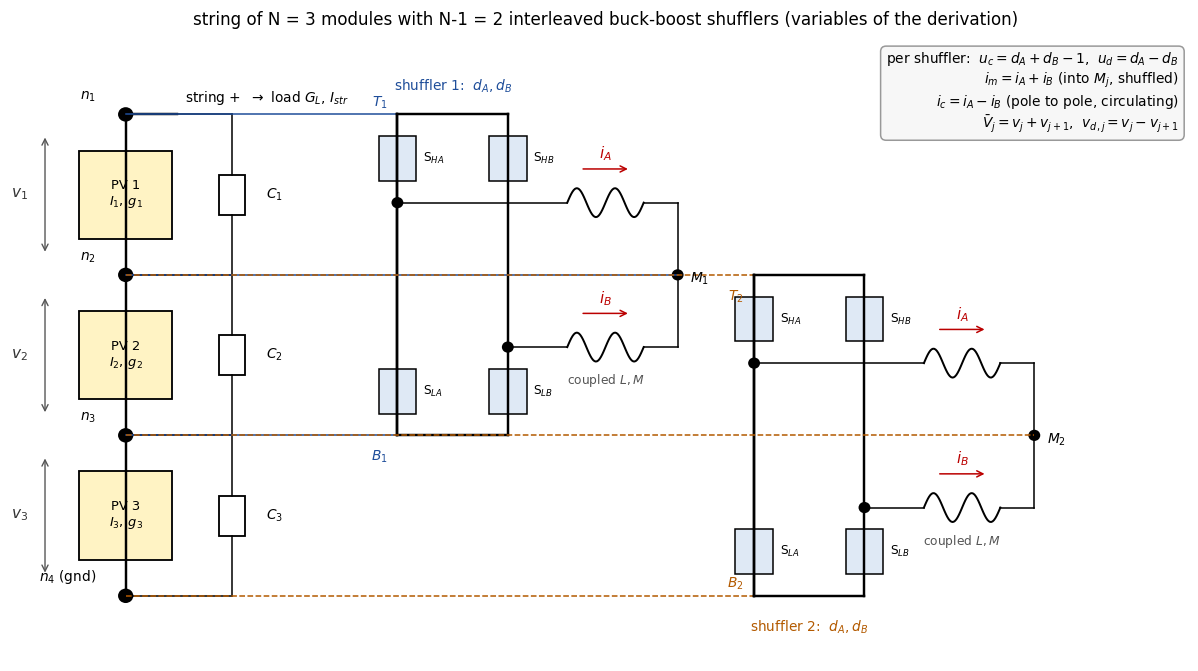

In [3]:
from matplotlib.patches import Rectangle, FancyArrowPatch, Circle
def draw_string(N=3, ax=None):
    ax = ax or plt.subplots(figsize=(11, 6.2))[1]
    ax.set_xlim(-1.2, 12.5); ax.set_ylim(-0.8, 2 * N + 1.0); ax.axis('off'); ax.grid(False)
    y = lambda k: 2 * (N + 1 - k)               # node n_k height, k = 1..N+1
    # modules (PV + capacitor + conductance) on the left rail
    for k in range(1, N + 1):
        yt, yb = y(k), y(k + 1)
        ax.plot([0, 0], [yb, yt], 'k', lw=1.6)
        ax.add_patch(Rectangle((-0.55, yb + 0.45), 1.1, 1.1, fc='#fff3c4', ec='k', lw=1.2))
        ax.text(0, yb + 1.0, f'PV {k}\n$I_{k},\,g_{k}$', ha='center', va='center', fontsize=8.5)
        ax.add_patch(Rectangle((1.1, yb + 0.75), 0.3, 0.5, fc='w', ec='k', lw=1.2)); ax.text(1.65, yb + 1.0, f'$C_{k}$', fontsize=9, va='center')
        ax.plot([0, 1.25], [yt, yt], 'k', lw=1.0); ax.plot([0, 1.25], [yb, yb], 'k', lw=1.0)
        ax.plot([1.25, 1.25], [yb, yb + 0.75], 'k', lw=1.0); ax.plot([1.25, 1.25], [yb + 1.25, yt], 'k', lw=1.0)
        ax.annotate('', xy=(-0.95, yb + 0.25), xytext=(-0.95, yt - 0.25), arrowprops=dict(arrowstyle='<->', lw=0.9, color='#555'))
        ax.text(-1.15, (yt + yb) / 2, f'$v_{k}$', ha='right', va='center', fontsize=10, color='#333')
    for k in range(1, N + 2):
        ax.add_patch(Circle((0, y(k)), 0.09, fc='k')); ax.text(-0.35, y(k) + 0.18, f'$n_{k}$' + (' (gnd)' if k == N + 1 else ''), fontsize=9, ha='right')
    ax.plot([0, 0.6], [y(1), y(1)], 'k', lw=1.6); ax.text(0.7, y(1) + 0.15, 'string +  $\\to$ load $G_L$, $I_{str}$', fontsize=9)
    # shufflers on the right, one per pair of modules
    cols = ['#1f4e9a', '#b35a00', '#2b7a3d', '#7a2b7a']
    for j in range(1, N):
        x0 = 3.2 + 4.2 * ((j - 1) % 2)        # alternate columns so neighbours do not overlap
        yT, yM, yB = y(j), y(j + 1), y(j + 2)
        cj = cols[(j - 1) % len(cols)]
        ax.plot([0, x0], [yT, yT], color=cj, lw=1.0, ls='-' if j % 2 else '--'); ax.plot([0, x0], [yB, yB], color=cj, lw=1.0, ls='-' if j % 2 else '--')
        ax.plot([x0, x0], [yB, yT], 'k', lw=1.6)
        for leg, (xl, lab) in enumerate(((x0 + 0.0, 'A'), (x0 + 1.3, 'B'))):
            ax.plot([xl, xl], [yB, yT], 'k', lw=1.6)
            for s, yy, name in ((0, yT - 0.55, f'S$_{{H{lab}}}$'), (1, yB + 0.55, f'S$_{{L{lab}}}$')):
                ax.add_patch(Rectangle((xl - 0.22, yy - 0.28), 0.44, 0.56, fc='#dfe9f5', ec='k', lw=1.0)); ax.text(xl + 0.3, yy, name, fontsize=8, va='center')
            ax.add_patch(Circle((xl, yM + 0.9 if leg == 0 else yM - 0.9), 0.07, fc='k'))
        ax.plot([x0, x0 + 1.3], [yT, yT], 'k', lw=1.6); ax.plot([x0, x0 + 1.3], [yB, yB], 'k', lw=1.6)
        # windings from the pole nodes to the midpoint
        ax.plot([x0, x0 + 2.0], [yM + 0.9, yM + 0.9], 'k', lw=1.0); ax.plot([x0 + 1.3, x0 + 2.0], [yM - 0.9, yM - 0.9], 'k', lw=1.0)
        for yy, lab, cur in ((yM + 0.9, 'A', '$i_A$'), (yM - 0.9, 'B', '$i_B$')):
            xs = np.linspace(x0 + 2.0, x0 + 2.9, 60); ax.plot(xs, yy + 0.18 * np.sin(np.linspace(0, 4 * np.pi, 60)), 'k', lw=1.3)
            ax.annotate('', xy=(x0 + 2.75, yy + 0.42), xytext=(x0 + 2.15, yy + 0.42), arrowprops=dict(arrowstyle='->', lw=1.0, color='#b00'))
            ax.text(x0 + 2.45, yy + 0.55, cur, color='#b00', fontsize=10, ha='center')
        ax.plot([x0 + 2.9, x0 + 3.3], [yM + 0.9, yM + 0.9], 'k', lw=1.0); ax.plot([x0 + 2.9, x0 + 3.3], [yM - 0.9, yM - 0.9], 'k', lw=1.0)
        ax.plot([x0 + 3.3, x0 + 3.3], [yM - 0.9, yM + 0.9], 'k', lw=1.0); ax.plot([0, x0 + 3.3], [yM, yM], color=cj, lw=1.0, ls='-' if j % 2 else '--')
        ax.add_patch(Circle((x0 + 3.3, yM), 0.07, fc='k'))
        ax.text(x0 + 2.45, yM - 1.32, 'coupled $L, M$', fontsize=8, ha='center', va='center', color='#555')
        ty = yT + 0.3 if j % 2 else yB - 0.45
        ax.text(x0 + 0.65, ty, f'shuffler {j}:  $d_A, d_B$', fontsize=9, ha='center', color=cj)
        ax.text(x0 + 3.45, yM - 0.05, f'$M_{j}$', fontsize=9, va='center')
        ax.text(x0 - 0.12, yT + (0.1 if j % 2 else -0.32), f'$T_{j}$', fontsize=9, ha='right', color=cj); ax.text(x0 - 0.12, yB - (0.32 if j % 2 else -0.1), f'$B_{j}$', fontsize=9, ha='right', color=cj)
    ax.text(12.4, 2 * N + 0.8, 'per shuffler:  $u_c = d_A + d_B - 1$,  $u_d = d_A - d_B$\n$i_m = i_A + i_B$ (into $M_j$, shuffled)\n$i_c = i_A - i_B$ (pole to pole, circulating)\n$\\bar V_j = v_j + v_{j+1}$,  $v_{d,j} = v_j - v_{j+1}$',
            fontsize=9, ha='right', va='top', bbox=dict(fc='#f7f7f7', ec='#999', boxstyle='round,pad=0.4'))
    ax.set_title(f'string of N = {N} modules with N-1 = {N-1} interleaved buck-boost shufflers (variables of the derivation)', fontsize=11)
    return ax
draw_string(3); plt.tight_layout(); plt.show()

| symbol | meaning | telemetry / code name |
|---|---|---|
| $n_k,\ \phi_k$ | node $k$ of the ladder and its potential; $n_{N+1}$ = ground | — |
| $v_k = \phi_k - \phi_{k+1}$ | voltage of module $k$ | `VMk` |
| $I_k$, $g_k$ | module current at the operating point and small-signal conductance $-\partial I/\partial v$ (PV: $\approx I_{mp}/V_{mp}$; CV supply: large; CC supply: 0) | `IMk` |
| $C_k$ | capacitance across module $k$ (the two shuffler capacitors that share the module, in parallel) | 130 µF / 260 µF |
| $G_L$, $I_{str}$ | load conductance at the top node, string current | `I_String` |
| $T_j, M_j, B_j$ | rails and midpoint of shuffler $j$: $n_j$, $n_{j+1}$, $n_{j+2}$; $\bar V_j = v_j + v_{j+1}$ | — |
| $d_A, d_B$ | high-side duties of legs A and B; $u_c = d_A + d_B - 1$ common, $u_d = d_A - d_B$ differential | `dAj, dBj`; `uc, ud` |
| $i_A, i_B$ | winding currents, positive from the pole through the winding **into** the midpoint | `ILA`, `-ILB` |
| $i_m = i_A + i_B$ | shuffled / injected current into $M_j$ (sum mode) | `ILA - ILB`, `ish` |
| $i_c = i_A - i_B$ | circulating pole-to-pole current (difference mode) | `ILA + ILB`, `ic` |
| $L, M$ | self and mutual inductance of the coupled windings (7.9 µH, 5.85 µH); $L_m = L - M$ for $i_m$, $L_c = L + M$ for $i_c$ (as built, §8.1) | — |
| $R_w$ | resistance of one winding path (copper 1.85 mΩ + switch + sense + traces); per mode $R_m$, $R_c$ | 61 mΩ Simulink, ~16 mΩ QSPICE devices |
| $v_{d,j} = v_j - v_{j+1}$ | controlled voltage of shuffler $j$ | `vd1, vd2` |
| $f_{sw}, T, t_d$ | switching frequency, period, dead time per edge (4 % of $T$) | 200 / 300 / 400 kHz |

## 2 · Switching states and the averaged model

Each shuffler has four switches in two legs. Of the $2^4 = 16$ gate combinations the 7 that short a leg are forbidden,
leaving **9 valid states**: 4 with one switch on in each leg (the *dual-switch* states), 4 with one leg in dead time and
1 with both legs in dead time. In a dead-time state the pole is not driven: the winding current chooses a body diode,
so the pole sits at $\phi_T + V_f$ or $\phi_B - V_f$ depending on the sign of the current. The averaged model keeps the
four dual-switch states with the dwell fractions of two independent carriers,

$$\{d_Ad_B,\ d_A(1-d_B),\ (1-d_A)d_B,\ (1-d_A)(1-d_B)\},$$

and treats the dead-time states as part of the neighbouring dual-switch state. Section 8 shows what that drops: nothing
at the average when the ripple dominates the DC current (the two dead times of a period cancel), but a *current-dependent
volt-second loss* once the pole capacitance is included, which is the "switching resistance" the identification found.

| state | leg A | leg B | pole A | pole B | dwell |
|---|---|---|---|---|---|
| 1 | high | high | $\phi_T$ | $\phi_T$ | $d_Ad_B$ |
| 2 | high | low | $\phi_T$ | $\phi_B$ | $d_A(1-d_B)$ |
| 3 | low | high | $\phi_B$ | $\phi_T$ | $(1-d_A)d_B$ |
| 4 | low | low | $\phi_B$ | $\phi_B$ | $(1-d_A)(1-d_B)$ |
| 5-8 | one leg dead | — | by $\mathrm{sgn}(i)$ | — | $2t_d/T$ each leg |
| 9 | both dead | — | by $\mathrm{sgn}(i_A)$ | by $\mathrm{sgn}(i_B)$ | overlap of the dead times |

Per state the circuit is linear: winding KVL with the coupled inductance matrix and KCL at the three nodes the shuffler
touches. `nstring_derive.switch_state` writes them, `averaged` takes the dwell-weighted sum:

In [4]:
st = nd.switch_state(1, 0)
print('state 2 (A high, B low):  d/dt [i_A, i_B] =', list(st['di']), '\n   current drawn from T:', st['i_from_T'], '  into M:', st['i_into_M'], '  from B:', st['i_from_B'])
av = nd.averaged()
print('\naveraged:  Lmat d/dt [i_A, i_B] = ', list(sp.simplify(nd.Lmat * av['di'])))
print('   drawn from T:', av['i_from_T'], '   into M:', av['i_into_M'], '   from B:', av['i_from_B'])

state 2 (A high, B low):  d/dt [i_A, i_B] = [(-L*(R*i_A + phi_M - phi_T) - M*(R*i_B - phi_B + phi_M))/(L**2 - M**2), (-L*(R*i_B - phi_B + phi_M) - M*(R*i_A + phi_M - phi_T))/(L**2 - M**2)] 
   current drawn from T: i_A   into M: i_A + i_B   from B: i_B



averaged:  Lmat d/dt [i_A, i_B] =  [-R*i_A - d_A*phi_B + d_A*phi_T + phi_B - phi_M, -R*i_B - d_B*phi_B + d_B*phi_T + phi_B - phi_M]
   drawn from T: d_A*i_A + d_B*i_B    into M: i_A + i_B    from B: -d_A*i_A - d_B*i_B + i_A + i_B


The averaged pole voltages are $v_{A} = \phi_B + d_A\bar V$, $v_B = \phi_B + d_B \bar V$, and the rails see the
duty-weighted winding currents: the top rail supplies $d_A i_A + d_B i_B$, the bottom rail $(1-d_A)i_A + (1-d_B)i_B$,
the midpoint receives $i_A + i_B$. These are exactly App. B's capacitor rows ("$C_1$ charged by every phase whose
high side is on") with the midpoint current made explicit, i.e. App. B *was* the as-built topology.

## 3 · KVL / KCL of the string: the averaged $N$-module model

**Winding modes.** With the as-built coupling (magnetising current $i_A - i_B$, inductance matrix
$\begin{bmatrix}L&-M\\-M&L\end{bmatrix}$) the sum and difference of the two winding equations decouple:

In [5]:
m = nd.modal()
print('(L - M) d i_m/dt =', m['rhs_sum'])
print('(L + M) d i_c/dt =', m['rhs_dif'])
print('rail currents in modal variables:', m['rails'])

(L - M) d i_m/dt = -R*i_m + u_c*v_j + u_c*v_{j+1} + v_j - v_{j+1}
(L + M) d i_c/dt = -R*i_c + u_d*v_j + u_d*v_{j+1}
rail currents in modal variables: {'i_from_T': i_c*u_d/2 + i_m*u_c/2 + i_m/2, 'i_into_M': i_m, 'i_from_B': -i_c*u_d/2 - i_m*u_c/2 + i_m/2}


$$\boxed{(L-M)\,\dot i_{m,j} = \bar V_j\,u_{c,j} + v_{d,j} - R_m\, i_{m,j}}\qquad
\boxed{(L+M)\,\dot i_{c,j} = \bar V_j\,u_{d,j} - R_c\, i_{c,j}}$$

The common duty drives the shuffled current against the module-voltage difference (volt-second balance: at DC
$v_{d,j} = -\bar V_j u_{c,j}$ up to the $R_m$ drop); the differential duty drives the circulating current against nothing
but $R_c$. The rails carry $\tfrac12 i_m (1 \pm u_c) \pm \tfrac12 i_c u_d$: at the operating point ($u_c, u_d, i_c \to 0$)
each rail supplies half of the shuffled current, which is what lets the modules share current.

**The ladder.** Module $k$ is a current source $I_k - g_k v_k$ in parallel with $C_k$ between $n_k$ and $n_{k+1}$;
the load is $G_L$ at $n_1$. Nodal KCL with the shuffler injections (+$i_{m,j}$ at $M_j$, $-\tfrac12 i_{m,j}$ at $T_j$ and
$B_j$) gives, in the node potentials $\phi$,

$$C_n\,\dot\phi = -G_n\,\phi + S\,i_m + w, \qquad v_{d,j} = \phi_j - 2\phi_{j+1} + \phi_{j+2},$$

with $C_n$, $G_n$ the standard nodal matrices of the chain, $S$ the injection pattern and $w$ the PV sources.
Together with the two winding equations per shuffler this is the whole model, $x = [\phi,\ i_m,\ i_c]$, $u = [u_c,\ u_d]$,
$y = [v_d,\ i_c]$. `nstring_derive.string_model(N)` builds it symbolically, `nstring.build_ss(p)` numerically; check
that the two agree for $N = 3$:

In [6]:
s3 = nd.string_model(3)
print('states:', list(s3['x']), '\ninputs:', list(s3['u']))
print('\nsymbolic A (N = 3):'); sp.pprint(s3['A'])
p = ns.pv80()
sy = s3['syms']
subs = {sy['Lm']: p.L_m, sy['Lc']: p.L_c, sy['Rm']: p.R_m, sy['Rc']: p.R_c, sy['GL']: p.G_load, sy['g'][0]: p.g[0]}
subs.update({sy['C'][k]: p.C[k] for k in range(3)}); subs.update({sy['Vb'][j]: p.Vbar(j) for j in range(2)})
A_sym = np.array(s3['A'].subs(subs), float); B_sym = np.array(s3['B'].subs(subs), float)
A_num, B_num, _, _, _ = ns.build_ss(p)
print('\nsymbolic == numeric (PV80):', np.allclose(A_sym, A_num, rtol=1e-9) and np.allclose(B_sym, B_num, rtol=1e-9))

states: [phi_1, phi_2, phi_3, i_m1, i_m2, i_c1, i_c2] 
inputs: [u_c1, u_c2, u_d1, u_d2]

symbolic A (N = 3):
⎡g⋅(C₂ + C₃)   (-G_L - g)⋅(C₁⋅C₂ + C₁⋅C₃ + C₂⋅C₃)  g    2⋅g⋅(C₂ + C₃)   g⋅(C₁⋅ ↪
⎢─────────── + ──────────────────────────────────  ── - ───────────── + ────── ↪
⎢   C₂⋅C₃                   C₁⋅C₂⋅C₃               C₃       C₂⋅C₃              ↪
⎢                                                                              ↪
⎢       g⋅(C₂ + C₃)   (C₂ + C₃)⋅(-G_L - g)                        g    g⋅(C₂ + ↪
⎢       ─────────── + ────────────────────                        ── - ─────── ↪
⎢          C₂⋅C₃             C₂⋅C₃                                C₃      C₂⋅C ↪
⎢                                                                              ↪
⎢                 g    -G_L - g                                                ↪
⎢                 ── + ────────                                          0     ↪
⎢                 C₃      C₃                                                   ↪


## 4 · Equilibrium: does the 2026 analysis still hold?

Set every derivative to zero with $d_A = d_B = D_j$ (the differential duty cannot persist: it would integrate $i_c$
without bound, so $U_d = 0$ and $I_c = 0$ at equilibrium, as in App. B).

**Volt-second balance** of shuffler $j$ (the sum-mode equation at DC):
$$D_j\,\bar V_j = v_{j+1} + \tfrac12 R_m I_{m,j} \;\;\Longrightarrow\;\; \boxed{\frac{D_j}{1-D_j} = \frac{v_{j+1}}{v_j}}\ \text{(to first order in } R_m).$$
App. B's $V_{C2}/V_{C1} = D/(1-D)$ survives unchanged for every shuffler in the string: **the duty is the voltage ratio**.

**Charge balance** at the interior nodes (module currents in, half of each neighbouring shuffler's current out):
$$I_{m,j} - (1-D_{j-1})\,I_{m,j-1} - D_{j+1}\,I_{m,j+1} = I_j - I_{j+1}\quad(j = 1..N-1,\ I_{m,0} = I_{m,N} = 0),$$
which at $D = \tfrac12$ is the tridiagonal system
$$\boxed{T(N)\,I_m = \Delta I,\qquad T = \mathrm{tridiag}(-\tfrac12,\ 1,\ -\tfrac12),\qquad (\Delta I)_j = I_j - I_{j+1}}$$
with the closed-form inverse $T^{-1}_{jk} = \tfrac{2}{N}\min(j,k)\,\big(N - \max(j,k)\big)$ (the Green's function of the
chain). Each shuffler carries a weighted sum of **all** mismatches, not just its own: that is the coupling beyond two
modules at DC. The top node then gives the string current,
$$\boxed{I_{str} = I_1 - D_1 I_{m,1} = \frac1N\sum_k I_k}$$
for $D = \tfrac12$: the shufflers make the string carry the **mean** module current, the ideal differential-power-processing
result, for any $N$. So, against the user's summary: the load current does not set the shuffled currents (the mismatch
does); it sets the module operating points through their $I$-$V$ curves, and the duties follow the resulting voltage ratios.

In [7]:
e3 = nd.equilibrium_symbolic(3)
print('T(3) =', e3['T'].tolist(), '   i_m =', [sp.simplify(v) for v in e3['i_m']], '   I_str =', e3['I_str'])
print('T(5)^-1 (closed form) =\n', ns.green(5), '\n check vs numeric inverse:', np.allclose(ns.green(5), np.linalg.inv(ns.laplacian(5))))
# check against the QSPICE S10i identification baseline: NGE103 channels in current limit at 0.8 / 1.0 / 1.3 A, all three at 23.3 V, D = 1/2
pq = ns.bench_qspice(R_w=0.29)        # R_m: the switching plant's effective value at 200 kHz (section 8)
eq = ns.equilibrium(pq, [0.8, 1.0, 1.3])
print('\nQSPICE S10i baseline (RUN 1, 200 kHz): measured  ish1 -0.464 A, ish2 -0.539 A, istr 1.024 A, vd1 -0.135 V, vd2 -0.158 V')
print(f"model:  i_m = {eq['i_m']},  I_str = {eq['I_str']:.3f} (mean {eq['I_mean']:.3f}),  R_m i_m = {eq['vd_drop']} V,  D = {eq['D']}")

T(3) = [[1, -1/2], [-1/2, 1]]    i_m = [4*I_1/3 - 2*I_2/3 - 2*I_3/3, 2*I_1/3 + 2*I_2/3 - 4*I_3/3]    I_str = I_1/3 + I_2/3 + I_3/3
T(5)^-1 (closed form) =
 [[1.6 1.2 0.8 0.4]
 [1.2 2.4 1.6 0.8]
 [0.8 1.6 2.4 1.2]
 [0.4 0.8 1.2 1.6]] 
 check vs numeric inverse: True

QSPICE S10i baseline (RUN 1, 200 kHz): measured  ish1 -0.464 A, ish2 -0.539 A, istr 1.024 A, vd1 -0.135 V, vd2 -0.158 V
model:  i_m = [-0.466 -0.534],  I_str = 1.032 (mean 1.033),  R_m i_m = [-0.135 -0.155] V,  D = [0.499 0.498]


The tridiagonal law reproduces the QSPICE shuffled currents to 1 % (−0.467 / −0.533 vs −0.464 / −0.539 A) and the
string current to 1 % (losses). The −0.135 V open-loop difference $v_1 - v_2$ at $D = \tfrac12$ is the $R_m I_m$ drop with
$R_m \approx 0.29\ \Omega$: the same effective resistance the circulating mode shows (section 8).

## 5 · Small signal and $G(N)$ in closed form

Linearising about the equilibrium ($u_c$ also moves the rail currents by $\pm\tfrac12 I_{m,0}u_c$, the only bilinear
term that survives) and taking $s\to0$:

In [8]:
s2 = nd.string_model(2)
print('G(2):'); sp.pprint(s2['G'])
print('\nG(3), equal module conductance g, voltage block (rows vd1, vd2; cols uc1, uc2):'); sp.pprint(sp.simplify(s3['G'][:2, :2]))
print('\ncirculating block:'); sp.pprint(s3['G'][2:, 2:])

G(2):
⎡  -V̅₁        ⎤
⎢────────   0 ⎥
⎢Rₘ⋅g + 1     ⎥
⎢             ⎥
⎢          V̅₁ ⎥
⎢   0      ───⎥
⎣          R_c⎦

G(3), equal module conductance g, voltage block (rows vd1, vd2; cols uc1, uc2):
⎡  -V̅₁⋅(4⋅Rₘ⋅g + 3)           2⋅Rₘ⋅V̅₂⋅g      ⎤
⎢─────────────────────  ─────────────────────⎥
⎢    2  2                   2  2             ⎥
⎢4⋅Rₘ ⋅g  + 8⋅Rₘ⋅g + 3  4⋅Rₘ ⋅g  + 8⋅Rₘ⋅g + 3⎥
⎢                                            ⎥
⎢      2⋅Rₘ⋅V̅₁⋅g          -V̅₂⋅(4⋅Rₘ⋅g + 3)   ⎥
⎢─────────────────────  ─────────────────────⎥
⎢    2  2                   2  2             ⎥
⎣4⋅Rₘ ⋅g  + 8⋅Rₘ⋅g + 3  4⋅Rₘ ⋅g  + 8⋅Rₘ⋅g + 3⎦

circulating block:
⎡V̅₁      ⎤
⎢───   0 ⎥
⎢R_c     ⎥
⎢        ⎥
⎢     V̅₂ ⎥
⎢ 0   ───⎥
⎣     R_c⎦


$$G(N) = \begin{bmatrix} G_v & 0 \\ 0 & \mathrm{diag}(\bar V_j / R_c)\end{bmatrix},\qquad
G_v = -\big(R_m I + Z_e\big)^{-1} Z_e\,\mathrm{diag}(\bar V_j),\qquad Z_e = -D_v\,G_n^{-1}\,S$$

where $Z_e$ is the transfer impedance of the ladder ($v_d$ per unit injected $i_m$). For a lossless winding
($R_m \to 0$) the voltage block is **diagonal**, $v_{d,j} = -\bar V_j u_{c,j}$: volt-second balance pins each shuffler's
own voltage difference whatever its neighbours do. The neighbour coupling at DC is the $O(R_m g)$ tridiagonal correction
($2R_m g\bar V/(4R_m^2g^2 + 8R_mg + 3)$ for $N = 3$): 1 % for PV modules, large only when the modules are stiff voltage
sources (bench PSU channels in CV, $g \approx 20$ S). The circulating block is diagonal and does not see the ladder at all.
This corrects the earlier reading of this notebook: $G(N)$ is not "tridiagonal because of the shared module"; the
sharing shows up in the **equilibrium currents** (§4) and in the **dynamics** (§7), not in the DC gain.

source                                                          vd1/uc1  vd2/uc2  vd1/uc2  ic1/ud1  ic2/ud2  vd1/ud1   cond
analytical PV80, averaged R_w 61 mOhm                             -40.4    -40.4      0.3    672.1    672.1      0.0   16.8
analytical PV80, switching R 0.29 ohm (200 kHz)                   -38.2    -38.2      1.3    141.4    141.4      0.0    3.8
analytical BENCH QSPICE op. point, R 0.29 ohm                     -46.6    -46.7     -0.1    160.7    160.7      0.0    3.5
analytical BENCH ch1 CC / ch2,3 CV, R 0.29 ohm                    -15.2     -7.2      2.4    155.2    172.4      0.0   26.3
identified sps-params-2.20261015-1950-3mod-qspice200-bench        -46.3    -46.9     -0.2    142.5    139.0    -24.7    3.2
identified sps-params-2.20261011-1634-3mod-qspice                 -37.4    -37.7      0.8    256.0    215.8      7.3    7.4
identified sps-params-2.20261015-1754-3mod-simulink-bench         -46.0    -47.4     -0.0    741.5    742.5     -0.6   16.1
identifi

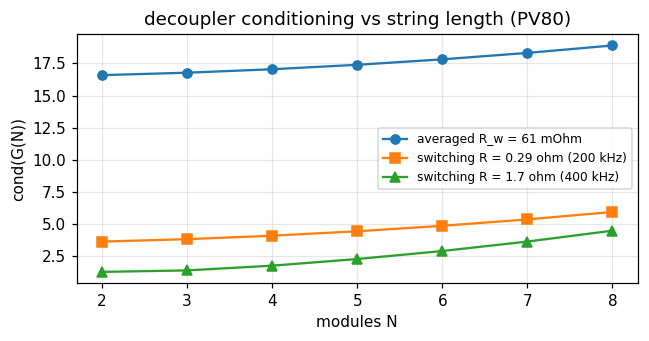

In [9]:
rows = []
for label, p in (('analytical PV80, averaged R_w 61 mOhm', ns.pv80()), ('analytical PV80, switching R 0.29 ohm (200 kHz)', ns.pv80(R_w=0.29)),
                 ('analytical BENCH QSPICE op. point, R 0.29 ohm', ns.bench_qspice(R_w=0.29)), ('analytical BENCH ch1 CC / ch2,3 CV, R 0.29 ohm', ns.bench(R_w=0.29))):
    rows.append((label, ns.dc_gain(p)))
for name, G in ns.identified_G().items():
    if not isinstance(G, str): rows.append(('identified ' + name, G))
print(f"{'source':62s} {'vd1/uc1':>8s} {'vd2/uc2':>8s} {'vd1/uc2':>8s} {'ic1/ud1':>8s} {'ic2/ud2':>8s} {'vd1/ud1':>8s} {'cond':>6s}")
for label, G in rows:
    print(f"{label:62s} {G[0,0]:8.1f} {G[1,1]:8.1f} {G[0,1]:8.1f} {G[2,2]:8.1f} {G[3,3]:8.1f} {G[0,2]:8.1f} {np.linalg.cond(G):6.1f}")
fig, ax = plt.subplots(figsize=(6, 3.2))
for lab, mk, R in (('averaged R_w = 61 mOhm', 'o-', ns.R_PHASE_SIM), ('switching R = 0.29 ohm (200 kHz)', 's-', 0.29), ('switching R = 1.7 ohm (400 kHz)', '^-', 1.7)):
    c = ns.cond_vs_N(lambda n, R=R: ns.pv80(N=n, R_w=R)); ax.plot(list(c), list(c.values()), mk, label=lab)
ax.set_xlabel('modules N'); ax.set_ylabel('cond(G(N))'); ax.legend(fontsize=8); ax.set_title('decoupler conditioning vs string length (PV80)')
plt.tight_layout(); plt.show()

Reading the table: the voltage gains agree with every identification once the operating point is right (the QSPICE
"bench" identification ran with all three channels in current limit, $g = 0$, so $G_v = -\bar V = -46.5$; the Simulink
bench identification with $-46$ as well). The circulating gains are $\bar V/R$ with $R$ the effective resistance of the
plant: 61 mΩ in the averaged Simulink model (742 identified), and 0.27 / 0.79 / 1.7 Ω in the switching model at
200 / 300 / 400 kHz (142 / 58 / 23 identified) — section 8 derives those numbers. The switching plant's $u_d \to v_d$ cross
term (−10 … −25 V/unit) is the only entry the averaged structure does not contain; it is second order ($i_c R$ asymmetry
of the two legs) and the identified decoupler absorbs it. Conditioning grows slowly with $N$ and is set by the ratio of
the two diagonal blocks, i.e. by $R$.

## 6 · Controllability and observability for $N$ modules

App. B: the differential mode needs $V_\Sigma \ne 0$, the common mode needs $\bar I \ne 0$ and $V_\Sigma \ne 0$, and the
differential current is invisible to voltage sensing. For the string, test every mode of $A$ with the PBH criterion
(smallest singular value of $[A - \lambda I,\ B]$ and $[A - \lambda I;\ C]$, scaled per unit):

In [10]:
def pbh_table(p, title):
    print(title, '  ranks:', ns.ranks(p))
    print(f"  {'mode':>9s} {'zeta':>5s}  {'ctrb u_c':>9s} {'ctrb u_d':>9s}  {'obsv y':>8s} {'obsv vd':>8s}   shape over [phi_1..phi_N | i_m | i_c]")
    for r in ns.pbh(p):
        print(f"  {r['f_hz']:7.0f} Hz {r['zeta']:5.2f}  {r['ctrb_u_c']:9.1e} {r['ctrb_u_d']:9.1e}  {r['obsv_y']:8.1e} {r['obsv_vd']:8.1e}   {r['shape']}")
pbh_table(ns.pv80(R_w=0.29), 'PV80, CV load, switching R (200 kHz)')
pbh_table(ns.pv80(R_w=0.29, G_load=1e-3), 'PV80, current-sink load')
pbh_table(ns.bench_qspice(R_w=0.29), 'QSPICE bench point (all channels CC)')
print('\nranks vs N (PV80, CV load):')
for N in (2, 3, 4, 6):
    print('  N =', N, ns.ranks(ns.pv80(N=N, R_w=0.29)))
# the string-sum direction: exactly unreachable with equal capacitors, weakly reachable with the real 130 / 260 / 130 uF
for lab, Cs in (('equal capacitors 173 uF', [173e-6] * 3), ('real 130 / 260 / 130 uF', [130e-6, 260e-6, 130e-6])):
    p_s = ns.Params(N=3, V=[20.5] * 3, g=[0.19] * 3, C=Cs, R_w=0.29, G_load=1e-3)
    r0 = ns.pbh(p_s)[0]
    A, B, Bw, C, D = ns.build_ss(p_s)
    print(f"{lab}: slowest mode {r0['f_hz']:.0f} Hz, shape {r0['shape']}, PBH ctrb {r0['ctrb_u']:.1e}, obsv {r0['obsv_y']:.1e};  DC gain u -> string voltage phi_1: {np.abs(-np.linalg.solve(A, B)[0]).max():.1e}")

PV80, CV load, switching R (200 kHz)   ranks: {'n': 7, 'ctrb_u': 7, 'ctrb_uc': 5, 'ctrb_ud': 2, 'obsv_y': 7, 'obsv_vd_only': 5}
       mode  zeta   ctrb u_c  ctrb u_d    obsv y  obsv vd   shape over [phi_1..phi_N | i_m | i_c]
     2622 Hz  1.00    7.4e-02   5.2e-17   2.5e-01  7.4e-02   [0.   0.01 0.01 1.   1.   0.   0.  ]
     3357 Hz  1.00    0.0e+00   4.9e-04   2.4e-01  0.0e+00   [0. 0. 0. 0. 0. 1. 0.]
     3357 Hz  1.00    0.0e+00   4.9e-04   2.4e-01  0.0e+00   [0. 0. 0. 0. 0. 0. 1.]
     4965 Hz  1.00    1.6e-01   1.5e-16   2.2e-01  1.6e-01   [0. 0. 0. 1. 1. 0. 0.]
    17928 Hz  1.00    9.8e-01   3.7e-17   5.9e-02  5.9e-02   [0. 0. 0. 1. 1. 0. 0.]
    20126 Hz  1.00    1.1e+00   2.7e-17   3.1e-02  3.1e-02   [0. 0. 0. 1. 1. 0. 0.]
    61185 Hz  1.00    1.9e-02   5.2e-16   4.5e-01  4.5e-01   [0.13 0.08 0.05 1.   1.   0.   0.  ]
PV80, current-sink load   ranks: {'n': 7, 'ctrb_u': 7, 'ctrb_uc': 5, 'ctrb_ud': 2, 'obsv_y': 7, 'obsv_vd_only': 5}
       mode  zeta   ctrb u_c  ctrb u_d    o

What changed and what did not:

* **The modal split survives for any $N$.** The $N-1$ circulating modes ($\lambda = -R_c/L_c$, one per shuffler) are reachable
  only from $u_d$ and observable only through the current sensors ("obsv vd" = 0): per-winding current sensing is still
  mandatory, exactly App. B §9. The voltage modes (ladder + $i_m$) are reachable only from $u_c$.
* **Conditions.** $\bar V_j \ne 0$ is still the only requirement on the circulating modes. The voltage modes no longer need
  $\bar I \ne 0$: in App. B the capacitor rows were driven by the duty through the inductor current ($B \propto \bar I$),
  whereas in the string the duty enters through the midpoint voltage $\bar V u_c$; the $\bar I$-dependent term is the small
  rail-current correction $\tfrac12 I_{m,0}u_c$. Duty saturation ($d \in [0.08, 0.92]$ in firmware) remains a hard limit.
* **One direction is special: the string-sum mode** (all module voltages moving together, "shape" $\phi \propto [N, N-1, \dots, 1]$,
  the slow 176 Hz mode with a current-sink load). With equal module capacitors it is exactly unreachable from the duties and
  unobservable from $v_d$ (PBH $10^{-16}$, last cell); with the real 130 / 260 / 130 µF it couples weakly through the
  capacitor asymmetry (PBH $10^{-3}$ against $10^{-1}$ for the other modes), and its DC gain from the duties is zero in both
  cases: the shufflers redistribute, they cannot move the total string voltage. It is stable only because the load ($G_L$,
  a 61 kHz mode with the CV load) or the PV conductances ($g_k$) pin it; with an ideal current sink and $g = 0$ it is the
  free integrator that broke the floating-capacitor LQR of 2026 (`shuffler_integrated` §10, "the capacitor common mode
  must be pinned"). In the string this mode belongs to the load / MPPT, which is why the supervisor and not the inner loop
  owns the string voltage.
* So the structural count for any $N$ is $n - 1 = 3N - 3$: the $N - 1$ module-voltage *differences* and the $2(N-1)$
  winding modes are what the $2(N-1)$ duties control and the $2(N-1)$ sensors see; the numerical PBH rank with the real
  capacitors is $n$ only through that weak asymmetric coupling.

## 7 · Modes and phase portraits with the real damping

`shuffler_statespace` §11 drew the resonant core as an undamped centre ($\zeta = 0.003$ with 1.85 mΩ) and argued that the
controller must supply the damping. The string model gives each shuffler a second-order voltage mode with the ladder's
effective capacitance $C_e$ and conductance $g_e$ (from $Z_e$: $v_{d,j} = -i_{m,j}/g_e$ at DC, $C_e \dot v_{d,j} = -i_{m,j}$ at
high frequency), and the real resistances:

$$f_0 = \frac{1}{2\pi\sqrt{L_m C_e}},\qquad \zeta = \tfrac12\Big(R_m\sqrt{C_e/L_m} + g_e\sqrt{L_m/C_e}\Big).$$

In [11]:
for label, p in (('2026 App. B values (2 x 100 uF, 38.7 V, R 1.85 mOhm, L+M)', ns.Params(N=2, V=[38.7]*2, g=[0.368]*2, C=[100e-6]*2, R_w=1.85e-3, G_load=1e-3, L_m=13.75e-6)),
                 ('same, as-built L-M in the sum mode', ns.Params(N=2, V=[38.7]*2, g=[0.368]*2, C=[100e-6]*2, R_w=1.85e-3, G_load=1e-3)),
                 ('PV80 string, averaged R_w 61 mOhm', ns.pv80()), ('PV80 string, switching R 0.29 ohm (200 kHz)', ns.pv80(R_w=0.29)),
                 ('PV80 string, switching R 1.7 ohm (400 kHz)', ns.pv80(R_w=1.7)), ('QSPICE bench point, R 0.29 ohm', ns.bench_qspice(R_w=0.29))):
    rv = ns.reduced_voltage_mode(p, 0)
    full = [(f'{f:.0f} Hz', f'z {z:.2f}') for f, z, k in ns.modes(p) if k == 'oscillatory']
    print(f"{label:52s} C_e {rv['C_e']*1e6:5.0f} uF  g_e {rv['g_e']:5.2f} S  f0 {rv['f0']/1e3:5.1f} kHz  zeta {rv['zeta']:.3f}   full model: {full}")

2026 App. B values (2 x 100 uF, 38.7 V, R 1.85 mOhm, L+M) C_e   100 uF  g_e  0.37 S  f0   4.3 kHz  zeta 0.071   full model: [('4294 Hz', 'z 0.07')]
same, as-built L-M in the sum mode                   C_e   100 uF  g_e  0.37 S  f0  11.1 kHz  zeta 0.033   full model: [('11120 Hz', 'z 0.03')]
PV80 string, averaged R_w 61 mOhm                    C_e   173 uF  g_e  0.19 S  f0   8.4 kHz  zeta 0.291   full model: [('6973 Hz', 'z 0.36'), ('9296 Hz', 'z 0.27')]
PV80 string, switching R 0.29 ohm (200 kHz)          C_e   173 uF  g_e  0.19 S  f0   8.4 kHz  zeta 1.344   full model: []
PV80 string, switching R 1.7 ohm (400 kHz)           C_e   173 uF  g_e  0.19 S  f0   8.4 kHz  zeta 7.826   full model: []
QSPICE bench point, R 0.29 ohm                       C_e   173 uF  g_e  0.00 S  f0   8.4 kHz  zeta 1.333   full model: []


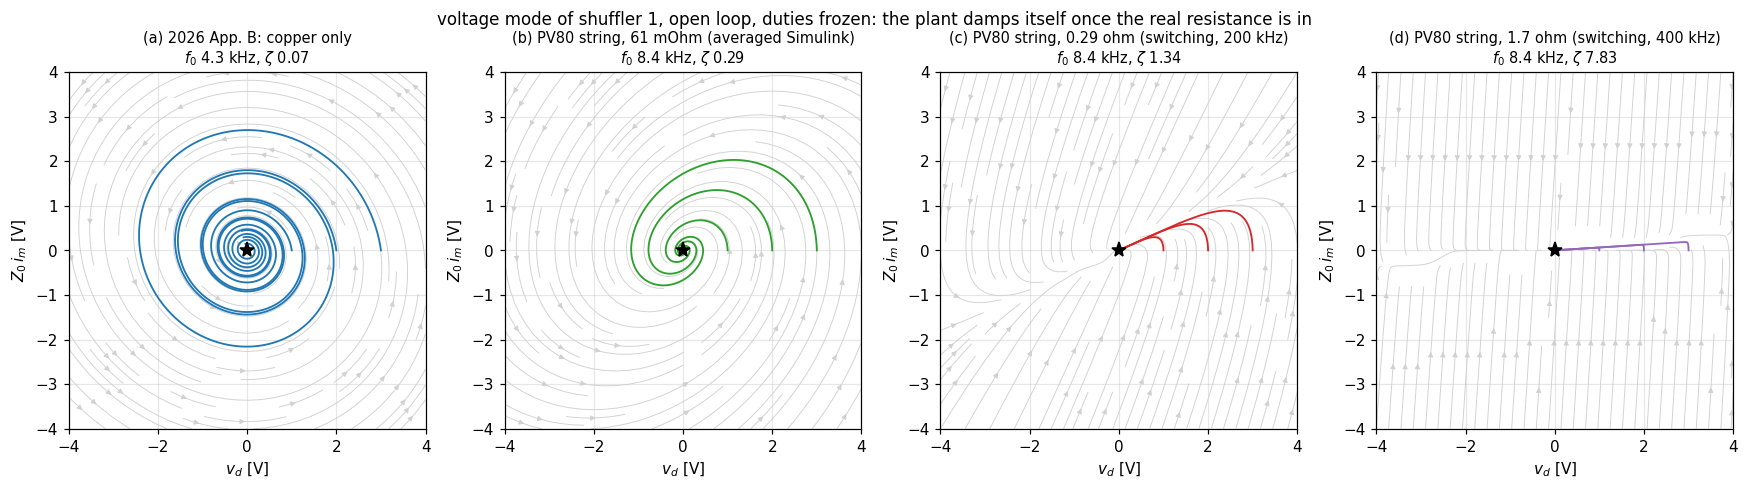

In [12]:
from scipy.integrate import solve_ivp
def portrait(ax, p, j, title, Tend=1.0e-3, v0s=(1.0, 2.0, 3.0), col='tab:blue'):
    rv = ns.reduced_voltage_mode(p, j); A2 = rv['A2']; Z0 = math.sqrt(p.L_m / rv['C_e'])
    V, P = np.meshgrid(np.linspace(-4, 4, 24), np.linspace(-4, 4, 24))          # axes: vd [V], Z0 i_m [V]
    dV = A2[0, 0] * V + A2[0, 1] * P / Z0; dP = Z0 * (A2[1, 0] * V + A2[1, 1] * P / Z0)
    nrm = np.hypot(dV, dP); nrm[nrm == 0] = 1
    ax.streamplot(V, P, dV / nrm, dP / nrm, color='0.82', density=1.0, linewidth=0.6, arrowsize=0.7)
    for v0 in v0s:
        s = solve_ivp(lambda t, z: A2 @ z, (0, Tend), [v0, 0.0], t_eval=np.linspace(0, Tend, 6000), rtol=1e-9, atol=1e-12)
        ax.plot(s.y[0], Z0 * s.y[1], color=col, lw=1.2)
    ax.plot(0, 0, 'k*', ms=10); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect('equal')
    ax.set_xlabel('$v_d$ [V]'); ax.set_ylabel('$Z_0\, i_m$ [V]'); ax.set_title(title + f"\n$f_0$ {rv['f0']/1e3:.1f} kHz, $\\zeta$ {rv['zeta']:.2f}", fontsize=9.5)
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
portrait(ax[0], ns.Params(N=2, V=[38.7]*2, g=[0.368]*2, C=[100e-6]*2, R_w=1.85e-3, G_load=1e-3, L_m=13.75e-6), 0, '(a) 2026 App. B: copper only')
portrait(ax[1], ns.pv80(), 0, '(b) PV80 string, 61 mOhm (averaged Simulink)', col='tab:green')
portrait(ax[2], ns.pv80(R_w=0.29), 0, '(c) PV80 string, 0.29 ohm (switching, 200 kHz)', col='tab:red')
portrait(ax[3], ns.pv80(R_w=1.7), 0, '(d) PV80 string, 1.7 ohm (switching, 400 kHz)', col='tab:purple')
fig.suptitle('voltage mode of shuffler 1, open loop, duties frozen: the plant damps itself once the real resistance is in', fontsize=11)
plt.tight_layout(); plt.show()

Panel (a) is the 2026 picture (the PV conductance alone gives $\zeta \approx 0.07$ with $L+M$, and the correct $L-M$
makes it 0.03). Panel (b) is the averaged Simulink string: a focus with $\zeta \approx 0.3$ at 7-9 kHz. Panels (c) and (d)
carry the switching resistance of section 8 and are **over-damped nodes** ($\zeta$ 1.3 at 200 kHz, 7.8 at 400 kHz): the
switching plant has no voltage-mode resonance to speak of. This is the quantitative form of decisions 2.3 / 3.2 / 3.4:
averaging deletes damping, the 61 mΩ restores enough of it that a static decoupler with an integral-only loop is
sufficient, and proportional action towards the kHz resonance is unnecessary (and, on the switching plant, pointless).

**Full-model trajectories.** The same planes for the complete $N = 3$ model under the deployed controller: the loop
closing on a module mismatch (the S1 scenario of the results synthesis) at three gains.

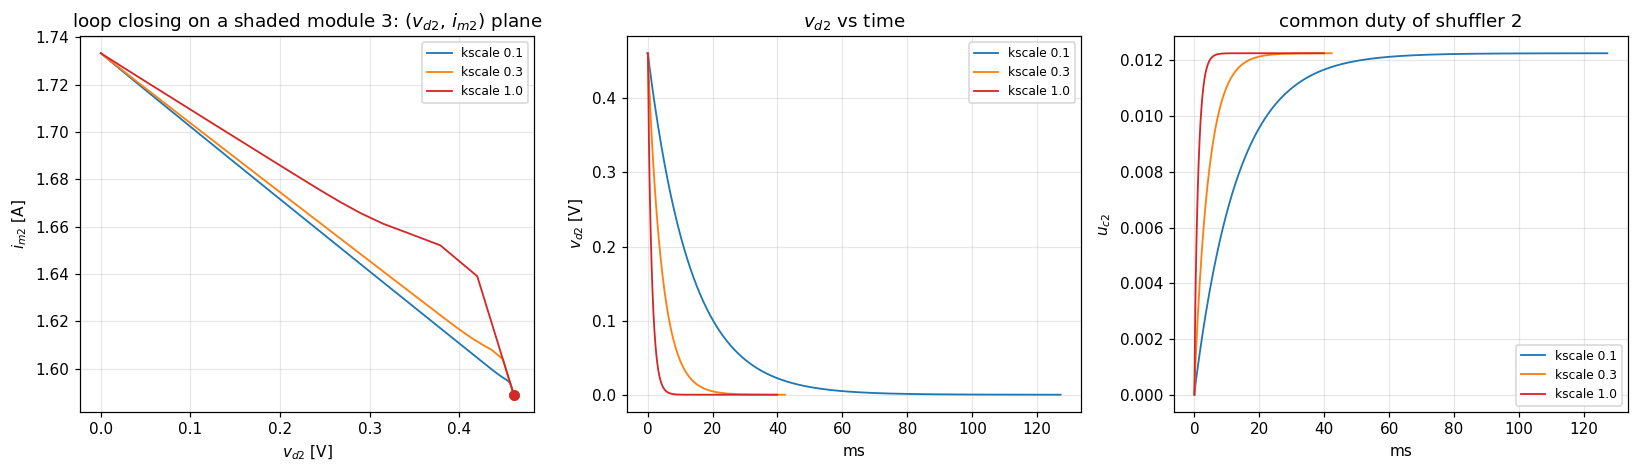

In [13]:
M = np.array(json.load(open(os.path.join(ns.PARAMS_DIR, 'shuffler_params.json')))['ctrl']['M'])
p = ns.pv80(R_w=0.29)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
w = np.zeros(3); w[2] = -1.3                      # module 3 loses 1.3 A (1/3 of Imp): the open-loop plant settles with a mismatch
for k, col in ((0.1, 'tab:blue'), (0.3, 'tab:orange'), (1.0, 'tab:red')):
    cl = ns.ClosedLoop(p, M=M, kscale=k)
    x0 = cl.ol_fixed_point(w)                      # open-loop equilibrium with duties at the operating point
    t, Y, U = cl.simulate(max(0.04, 12 / (k * ns.KI_V)), w=lambda tt: w, x0=x0)
    X = cl.X                                       # columns [phi_1, phi_2, phi_3, i_m1, i_m2, i_c1, i_c2]
    vd2 = Y[:, 1]; im2 = X[:, 4]
    ax[0].plot(vd2, im2, color=col, lw=1.2, label=f'kscale {k}'); ax[0].plot(vd2[0], im2[0], 'o', color=col)
    ax[1].plot(t * 1e3, vd2, color=col, lw=1.2, label=f'kscale {k}')
    ax[2].plot(t * 1e3, U[:, 1], color=col, lw=1.2, label=f'kscale {k}')
ax[0].set_xlabel('$v_{d2}$ [V]'); ax[0].set_ylabel('$i_{m2}$ [A]'); ax[0].set_title('loop closing on a shaded module 3: ($v_{d2}$, $i_{m2}$) plane'); ax[0].legend(fontsize=8)
ax[1].set_xlabel('ms'); ax[1].set_ylabel('$v_{d2}$ [V]'); ax[1].set_title('$v_{d2}$ vs time'); ax[1].legend(fontsize=8)
ax[2].set_xlabel('ms'); ax[2].set_ylabel('$u_{c2}$'); ax[2].set_title('common duty of shuffler 2'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The closed-loop trajectory is a first-order approach along the $i_m = -g_e v_d$ line (the rank-1 slope of the
retrospective: the injected current is slaved to the voltage difference), with the gain setting only the speed. The
kHz resonance is invisible at these bandwidths — the design separation of decision 0.2 holds with three orders of magnitude.

## 8 · The switching twin: ripple, coupling sense, dead time, and the origin of the switching resistance

`nswitch.py` keeps the ladder and the coupled windings but switches every half bridge: sawtooth carriers at $f_{sw}$,
leg B 180° behind leg A, dead time 4 % of the period at both edges, body diodes during dead time, optionally a pole
capacitance $C_p = 2C_{oss}$. The plant is linear inside each switch configuration, so the integrator is exact
($\Phi = e^{A_s h}$ per configuration, cached). The questions:

1. which winding mode sees $L + M$ (decision 1.4, the retrospective's $L_2$ fit);
2. does the averaged model reproduce the switching plant once the ripple is averaged out;
3. where the switching plant's "effective resistance" (0.27 Ω at 200 kHz, 1.7 Ω at 400 kHz) comes from.

### 8.1 · Coupling sense and ripple
With leg B 180° behind leg A at $d = \tfrac12$ the pole difference $v_A - v_B$ is a $\pm\bar V$ square wave, so the
**circulating** mode carries the switching ripple, $\Delta i_c = \bar V T / (2 L_c)$, while the sum mode is not excited.
QSPICE's ERUC23 subcircuit (turns 1 : −1, magnetising branch between the two windings) makes the magnetising current
$i_A - i_B$: the circulating mode sees $L + M = 13.75$ µH, the shuffled mode the leakage $L - M = 2.05$ µH. The switching
twin with both senses, against the QSPICE ripple of the sweep in `data/`:

                                    ic pp [A]  iA pp [A]  im pp [A]


nswitch 200 kHz, inverse  coupling       8.54       4.39       0.57


nswitch 200 kHz, direct   coupling      57.34      28.64       0.07
QSPICE  200 kHz (S10i, STD45N10F7)              8.39       4.25       0.19    formula V T/2(L+M) = 8.45


nswitch 400 kHz, inverse  coupling       4.24       2.19       0.28


nswitch 400 kHz, direct   coupling      28.41      14.21       0.03
QSPICE  400 kHz (S10i, STD45N10F7)              4.09       2.18       0.39    formula V T/2(L+M) = 4.23


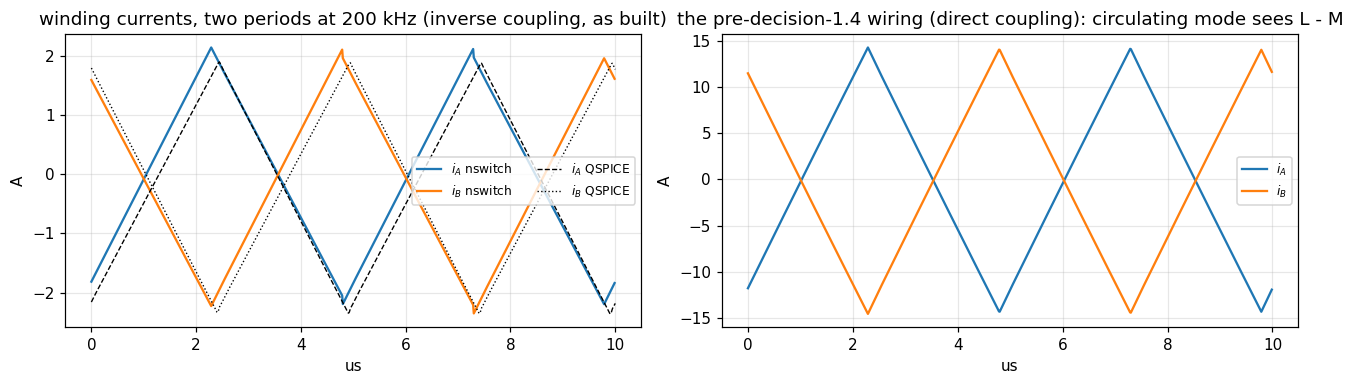

In [14]:
sweep = json.load(open(os.path.join(DATA, 'qspice_ud_sweep.json')))
qbase = {r['f_khz']: r for r in sweep if r['run'] == 1}
pq = ns.bench_qspice(R_w=ns.R_PHASE_SW)
print(f"{'':34s} {'ic pp [A]':>10s} {'iA pp [A]':>10s} {'im pp [A]':>10s}")
for f in (200e3, 400e3):
    for sense in ('inverse', 'direct'):
        pp = ns.bench_qspice(R_w=ns.R_PHASE_SW, coupling=sense)
        r = sw.simulate(pp, f_sw=f, T=1.0e-3, cfg=sw.SwitchCfg(f_sw=f, I_mod=[0.8, 1.0, 1.3]), record_every=2)
        a, b = 1.0e-3 - 4 / f, 1.0e-3
        print(f"nswitch {int(f/1e3)} kHz, {sense:8s} coupling {sw.ripple_pp(r['t'], r['ic'][:, 0], a, b):10.2f} {sw.ripple_pp(r['t'], r['iA'][:, 0], a, b):10.2f} {sw.ripple_pp(r['t'], r['im'][:, 0], a, b):10.2f}")
    r = None
    q = qbase[int(f / 1e3)]
    print(f"QSPICE  {int(f/1e3)} kHz (S10i, STD45N10F7)        {q['ic1_pp']:10.2f} {q['iA1_pp']:10.2f} {q['im1_pp']:10.2f}    formula V T/2(L+M) = {46.5/(2*f*13.75e-6):.2f}")
npz = np.load(os.path.join(DATA, 'qspice_ud_sweep.npz'))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
r = sw.simulate(pq, f_sw=200e3, T=2.0e-3, cfg=sw.SwitchCfg(f_sw=200e3, I_mod=[0.8, 1.0, 1.3]), record_every=1)
m = r['t'] >= 2.0e-3 - 2 / 200e3
ax[0].plot((r['t'][m] - r['t'][m][0]) * 1e6, r['iA'][m, 0], label='$i_A$ nswitch'); ax[0].plot((r['t'][m] - r['t'][m][0]) * 1e6, r['iB'][m, 0], label='$i_B$ nswitch')
ax[0].plot(npz['f200_run1_du0/t_ripple'] * 1e6, npz['f200_run1_du0/iA1_ripple'], 'k--', lw=0.9, label='$i_A$ QSPICE'); ax[0].plot(npz['f200_run1_du0/t_ripple'] * 1e6, npz['f200_run1_du0/iB1_ripple'], 'k:', lw=0.9, label='$i_B$ QSPICE')
ax[0].set_xlabel('us'); ax[0].set_ylabel('A'); ax[0].set_title('winding currents, two periods at 200 kHz (inverse coupling, as built)'); ax[0].legend(fontsize=8, ncol=2)
rd = sw.simulate(ns.bench_qspice(R_w=ns.R_PHASE_SW, coupling='direct'), f_sw=200e3, T=2.0e-3, cfg=sw.SwitchCfg(f_sw=200e3, I_mod=[0.8, 1.0, 1.3]), record_every=1)
ax[1].plot((rd['t'][m] - rd['t'][m][0]) * 1e6, rd['iA'][m, 0], label='$i_A$'); ax[1].plot((rd['t'][m] - rd['t'][m][0]) * 1e6, rd['iB'][m, 0], label='$i_B$')
ax[1].set_xlabel('us'); ax[1].set_ylabel('A'); ax[1].set_title('the pre-decision-1.4 wiring (direct coupling): circulating mode sees L - M'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The as-built sense gives the ±2 A per winding that QSPICE shows; the other sense gives the ±25 A (±47 A at the 2026
module voltage) that forced decision 1.4. So: **$i_c$ sees $L+M$, $i_m$ sees $L-M$**. The retrospective's "$L_2 = 12.6$ µH from
the 6.34 kHz resonance" assumed $C/2$ and $L+M$ in the voltage mode; with $C_e = C$ (§7) and $L - M$ the two-module
voltage mode sits near 11 kHz, and the 6.34 kHz of the June identification stays attributed to that Simulink model's own
inductor wiring (open item).

### 8.2 · Averaged vs switched: step responses
A $u_c$ step and a $u_d$ step on shuffler 1 at the QSPICE bench point; the switched currents are averaged over the
100 µs firmware tick and overlaid on the averaged model with the same parameters.

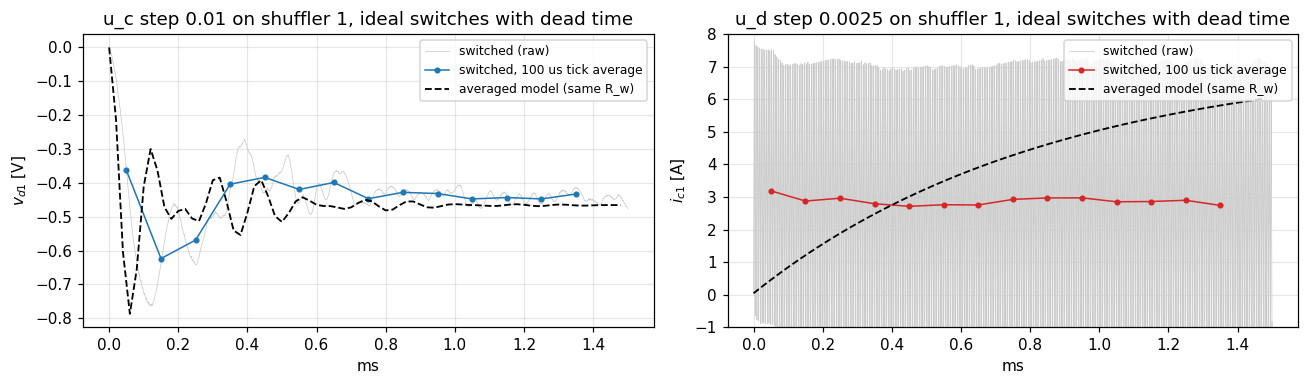

In [15]:
p_av = ns.bench_qspice(R_w=ns.R_PHASE_SW)
A, B, Bw, C, D = ns.build_ss(p_av)
Ad, Bd = ns.discretise(A, B, 20e-6)
def averaged_step(uvec, T=1.5e-3, dt=20e-6):
    n = int(T / dt); x = np.zeros(A.shape[0]); out = np.zeros((n, C.shape[0]))
    for k in range(n):
        out[k] = C @ x; x = Ad @ x + Bd @ uvec
    return np.arange(n) * dt, out
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i, (lab, du, dA, dB, col) in enumerate((('u_c step 0.01 on shuffler 1', 0.01, [0.505, 0.5], [0.505, 0.5], 'tab:blue'), ('u_d step 0.0025 on shuffler 1', 0.0025, [0.50125, 0.5], [0.49875, 0.5], 'tab:red'))):
    r = sw.simulate(p_av, f_sw=200e3, T=1.5e-3, dA=np.array(dA), dB=np.array(dB), cfg=sw.SwitchCfg(f_sw=200e3, I_mod=[0.8, 1.0, 1.3]), record_every=2)
    tt, yt = sw.tick_average(r['t'], np.column_stack([r['vd'][:, 0], r['ic'][:, 0]]), 100e-6)
    u = np.zeros(4); u[0 if i == 0 else 2] = du
    ta, ya = averaged_step(u)
    sig, name = (0, '$v_{d1}$ [V]') if i == 0 else (1, '$i_{c1}$ [A]')
    sig_av = 0 if i == 0 else 2                              # averaged-model outputs are [vd1, vd2, ic1, ic2]
    ax[i].plot(r['t'] * 1e3, (r['vd'][:, 0] if i == 0 else r['ic'][:, 0]), color='0.8', lw=0.5, label='switched (raw)')
    ax[i].plot(tt * 1e3, yt[:, sig], 'o-', color=col, ms=3, lw=1, label='switched, 100 us tick average')
    ax[i].plot(ta * 1e3, ya[:, sig_av] + (r['vd'][0, 0] if i == 0 else r['ic'][0, 0]), 'k--', lw=1.2, label='averaged model (same R_w)')
    ax[i].set_xlabel('ms'); ax[i].set_ylabel(name); ax[i].set_title(lab + ', ideal switches with dead time'); ax[i].legend(fontsize=8)
    if i == 1: ax[i].set_ylim(-1, 8)
plt.tight_layout(); plt.show()

The voltage mode agrees: same final value, same 8 kHz ring (the tick average smooths it). The circulating mode does
**not**: with ideal switches the averaged model
predicts $\bar V u_d / R_w = 7$ A and a 0.9 ms time constant ($L_c/R_w$), the switched plant snaps to about 3 A in a
few periods and stays there. That is the first dead-time effect: as long as the DC current of a leg is smaller than half
its ripple ($|I| < \Delta i/2$), the two dead times of a period see opposite current signs and cancel; once the loop current
pushes a leg's DC past half the ripple the dead time subtracts $2t_d f_{sw}\bar V$ (0.08 $\bar V$) from that leg's average
voltage — far more than any $u_d$ the loop ever applies. So the ideal-switch plant has a dead-band characteristic:
$\bar V/R_w$ up to $i_c \approx \Delta i_c/2$, then a plateau. The QSPICE plant does something else again (§8.3).

### 8.3 · The static characteristic $i_c(u_d)$: QSPICE sweep, switching twin, and the formula
`data/qspice_ud_sweep.json`: open-loop $u_d$ steps 0.0025 … 0.08 on shuffler 1 of the bench S10i netlist at 200 and
400 kHz (QSPICE, STD45N10F7 + 1ED3140 models); `data/nswitch_static.json`: the same with `nswitch`, ideal switches and
with $C_p = 2.2$ nF ($2 C_{oss}$ of the device model at the operating voltage).

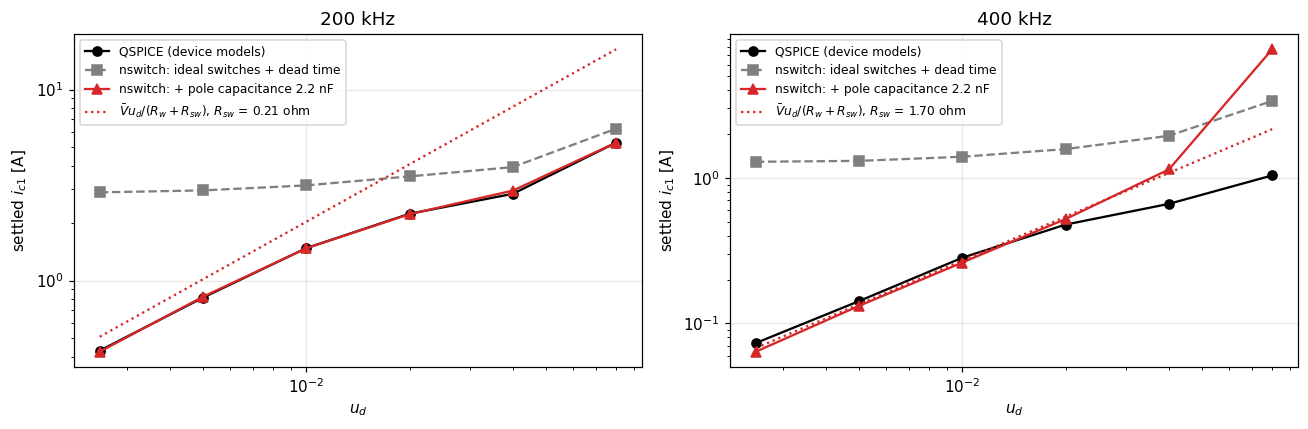

    u_d |  QSPICE 200k  ideal 200k  C_p 200k |  QSPICE 400k  ideal 400k  C_p 400k   [A per unit u_d]
 0.0025 |          172        1158       170 |           29         516        26
 0.0050 |          163         593       165 |           28         262        26
 0.0100 |          148         315       148 |           28         140        26
 0.0200 |          112         175       111 |           24          79        26
 0.0400 |           71          98        74 |           17          49        29
 0.0800 |           66          78        66 |           13          42        96

QSPICE discriminator (u_d = 0.01, A per unit):
  200 kHz: full model    148   no reverse recovery    147   no device capacitances    239
  400 kHz: full model     28   no reverse recovery     28   no device capacitances    114


In [16]:
stat = json.load(open(os.path.join(DATA, 'nswitch_static.json')))
qs = {f: sorted([r for r in sweep if r['run'] == 4 and r['f_khz'] == f], key=lambda r: r['du']) for f in (200, 400)}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, f in enumerate((200, 400)):
    du = np.array([r['du'] for r in qs[f]])
    ax[i].plot(du, [r['ic1'] for r in qs[f]], 'ko-', label='QSPICE (device models)')
    ax[i].plot(du, [r['ic'] for r in stat[f'ideal_f{f}']], 's--', color='tab:gray', label='nswitch: ideal switches + dead time')
    ax[i].plot(du, [r['ic'] for r in stat[f'cp2n_f{f}']], '^-', color='tab:red', label='nswitch: + pole capacitance 2.2 nF')
    Lc = 13.75e-6; Rsw = 64 * 2.2e-9 * (f * 1e3) ** 3 * Lc ** 2
    ax[i].plot(du, du * 46.5 / (ns.R_PHASE_SW + Rsw), ':', color='tab:red', lw=1.5, label=f'$\\bar V u_d / (R_w + R_{{sw}})$, $R_{{sw}}$ = {Rsw:.2f} ohm')
    ax[i].set_xscale('log'); ax[i].set_yscale('log'); ax[i].set_xlabel('$u_d$'); ax[i].set_ylabel('settled $i_{c1}$ [A]'); ax[i].set_title(f'{f} kHz'); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"{'u_d':>7s} | {'QSPICE 200k':>12s} {'ideal 200k':>11s} {'C_p 200k':>9s} | {'QSPICE 400k':>12s} {'ideal 400k':>11s} {'C_p 400k':>9s}   [A per unit u_d]")
for k in range(6):
    g = lambda rows: rows[k]['ic'] / rows[k]['du'] if 'ic' in rows[k] else rows[k]['ic1'] / rows[k]['du']
    print(f"{qs[200][k]['du']:7.4f} | {g(qs[200]):12.0f} {g(stat['ideal_f200']):11.0f} {g(stat['cp2n_f200']):9.0f} | {g(qs[400]):12.0f} {g(stat['ideal_f400']):11.0f} {g(stat['cp2n_f400']):9.0f}")
disc = json.load(open(os.path.join(DATA, 'qspice_ideal_switch.json')))
print('\nQSPICE discriminator (u_d = 0.01, A per unit):')
for f in (200, 400):
    row = {r['variant']: r for r in disc if r['f_khz'] == f and r['run'] == 4}
    full = [r for r in qs[f] if abs(r['du'] - 0.01) < 1e-9][0]
    print(f"  {f} kHz: full model {full['ic1']/0.01:6.0f}   no reverse recovery {row['norr']['ic1']/0.01:6.0f}   no device capacitances {row['nocap']['ic1']/0.01:6.0f}")

Three facts fall out:

* the **ideal-switch plateau** of §8.2 is not what QSPICE does; the device plant is linear at small signal with a slope of
  170 A/unit at 200 kHz and 28 A/unit at 400 kHz;
* adding one physical parameter, the **pole capacitance** $C_p = 2C_{oss}$, makes the switching twin reproduce QSPICE point
  for point (170 / 165 / 148 / 111 / 74 / 66 vs 172 / 163 / 148 / 112 / 71 / 66 A per unit at 200 kHz; 26 vs 28 at 400 kHz);
* the QSPICE discriminator confirms the attribution: removing the body-diode reverse recovery changes nothing, removing
  the device capacitances lifts the gain (and leaves the ideal-switch plateau physics).

**Why a capacitance looks like a resistance.** In the ripple-dominated regime every commutation is resonant: after a
switch turns off, the winding current $i_e$ at that edge charges the pole capacitance and the pole slews over
$\tau_e = \bar V C_p / |i_e|$. At the high-side turn-off the current is at its peak, $i_1 = I + \Delta i/2$, and the slow fall
*adds* $\tfrac12 \bar V\tau_1$ of volt-seconds to the high state; at the low-side turn-off the current is at its valley,
$i_2 = I - \Delta i/2$, and the slow rise *removes* $\tfrac12\bar V\tau_2$. Per period the pole therefore loses

$$\bar V\,\frac{\tau_2 - \tau_1}{2} = \frac{\bar V^2 C_p}{2}\Big(\frac{1}{\Delta i/2 - I} - \frac{1}{\Delta i/2 + I}\Big)
\approx \frac{4\bar V^2 C_p}{\Delta i^2}\, I ,$$

a volt-second loss proportional to the leg's DC current, i.e. a resistance $R_{sw} = 4\bar V^2 C_p f_{sw}/\Delta i^2$ in series
with every winding path. With the per-leg ripple $\Delta i = \bar V/(4 f_{sw} L_c)$ the voltage cancels:

$$\boxed{R_{sw} = 64\, C_p\, f_{sw}^3\, (L+M)^2}$$

valid while the commutation finishes inside the dead time ($\tau_e < t_d$) and $|I| \ll \Delta i/2$. For $C_p = 2.2$ nF and
$L + M = 13.75$ µH: 0.21 Ω at 200 kHz, 0.72 Ω at 300 kHz, 1.70 Ω at 400 kHz, against 0.27 / 0.79 / 1.66 Ω implied by the
identified gains 142 / 58 / 23 A per unit (and the 0.29 / 1.47 Ω of the open-loop $v_d$ drop in the sum mode, which sees
the same per-leg loss). The cubic law is the "$\approx f^{2.6}$" collapse of the circulating gain with switching frequency, it
is independent of $\bar V$, and it is why the 400 kHz firmware image behaved as if the inductor had grown a 1.7 Ω resistor.

### 8.4 · What the averaged model needs, then
One line: $R_w \to R_w + R_{sw}(f_{sw})$ in both winding modes. The 61 mΩ "MOSFET $R_{ds(on)}$" of the averaged Simulink
model (decision 3.2) was the right fix for the wrong reason: it stands in for a switching loss that is not resistive in
origin, and its value is tied to one switching frequency. The table below is $G(3)$ with that substitution against
the identified gain sets:

In [17]:
print(f"{'f_sw':>6s} {'R_sw formula':>13s} {'R_w + R_sw':>11s} {'Vbar/R (model)':>15s} {'identified ic/ud':>17s}")
ident = {200: 140.8, 300: 57.8, 400: 23.2}
for f in (200, 300, 400):
    Rsw = 64 * 2.2e-9 * (f * 1e3) ** 3 * 13.75e-6 ** 2
    print(f"{f:5d}k {Rsw:13.3f} {ns.R_PHASE_SW + Rsw:11.3f} {46.5 / (ns.R_PHASE_SW + Rsw):15.0f} {ident[f]:17.1f}")

  f_sw  R_sw formula  R_w + R_sw  Vbar/R (model)  identified ic/ud
  200k         0.213       0.229             203             140.8
  300k         0.719       0.735              63              57.8
  400k         1.704       1.720              27              23.2


## 9 · Closed loop with the deployed controller

The firmware runs $u = k\,(M_p e + M \xi)$, $\xi \mathrel{+}= T_s e$, on a 2 kHz first-order filtered $y$ at
$T_s = 100$ µs with one tick of delay (`nstring.ClosedLoop`). With the model's own $M = G^{-1}\mathrm{diag}(k_I)$ the loops
are first order at $k_I$; with the deployed $M$ (identified on the QSPICE switching plant at 200 kHz) the poles show the
plant / decoupler mismatch. The plant here carries $R_w + R_{sw}(200\ \mathrm{kHz})$.

deployed gain set: sps-params-2.20261015-1950-3mod-qspice200-bench
kscale 0.1:  design tau_v 10.61 ms, tau_i 3.98 ms
   model M    : [('15 Hz', 'z 1.00'), ('15 Hz', 'z 1.00'), ('41 Hz', 'z 1.00'), ('41 Hz', 'z 1.00')]
   deployed M : [('12 Hz', 'z 1.00'), ('13 Hz', 'z 1.00'), ('41 Hz', 'z 1.00'), ('42 Hz', 'z 1.00')]
kscale 0.3:  design tau_v 3.54 ms, tau_i 1.33 ms
   model M    : [('46 Hz', 'z 1.00'), ('46 Hz', 'z 1.00'), ('134 Hz', 'z 1.00'), ('134 Hz', 'z 1.00')]
   deployed M : [('36 Hz', 'z 1.00'), ('39 Hz', 'z 1.00'), ('132 Hz', 'z 1.00'), ('136 Hz', 'z 1.00')]
kscale 1.0:  design tau_v 1.06 ms, tau_i 0.40 ms
   model M    : [('160 Hz', 'z 1.00'), ('164 Hz', 'z 1.00'), ('593 Hz', 'z 1.00'), ('593 Hz', 'z 1.00')]
   deployed M : [('127 Hz', 'z 1.00'), ('135 Hz', 'z 1.00'), ('582 Hz', 'z 1.00'), ('604 Hz', 'z 1.00')]
PV80, +1 V step on the VM2-VM3 reference (same metric definition as 8_Results/analysis)


  kscale 0.1: rise 28.42 ms  t_settle2  50.6 ms  overshoot 0.01 %  tau 12.90 ms  ss err -0.0002 V


  kscale 0.3: rise  9.35 ms  t_settle2  16.7 ms  overshoot 0.00 %  tau 4.21 ms  ss err -0.0000 V
  kscale 1.0: rise  2.59 ms  t_settle2   4.8 ms  overshoot 0.00 %  tau 1.16 ms  ss err -0.0000 V
BENCH (QSPICE S10 point), +1 V step on the VM2-VM3 reference
  kscale 0.1: rise 23.23 ms  t_settle2  41.3 ms  overshoot 0.00 %  tau 10.54 ms  ss err -0.0000 V


  kscale 0.3: rise  7.61 ms  t_settle2  13.6 ms  overshoot 0.00 %  tau 3.42 ms  ss err -0.0000 V
  kscale 1.0: rise  2.04 ms  t_settle2   3.8 ms  overshoot 0.00 %  tau 0.91 ms  ss err -0.0000 V


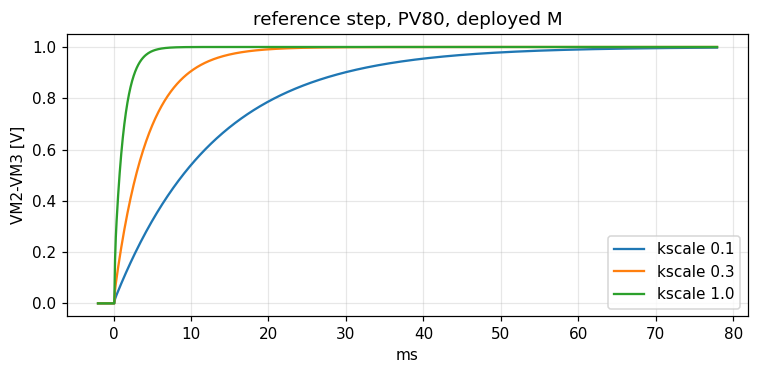

In [18]:
M, ver = np.array(json.load(open(os.path.join(ns.PARAMS_DIR, 'shuffler_params.json')))['ctrl']['M']), json.load(open(os.path.join(ns.PARAMS_DIR, 'shuffler_params.json')))['version']
print('deployed gain set:', ver)
p_cl = ns.pv80(R_w=0.29)
for k in (0.1, 0.3, 1.0):
    own = ns.ClosedLoop(p_cl, kscale=k).poles()[:4]
    dep = ns.ClosedLoop(p_cl, M=M, kscale=k).poles()[:4]
    d = ns.design_numbers(k)
    print(f"kscale {k}:  design tau_v {d['vd']['tau']*1e3:.2f} ms, tau_i {d['ic']['tau']*1e3:.2f} ms")
    print('   model M    :', [(f'{f:.0f} Hz', f'z {z:.2f}') for f, z in own])
    print('   deployed M :', [(f'{f:.0f} Hz', f'z {z:.2f}') for f, z in dep])
def metrics_table(p, label):
    print(label)
    for k in (0.1, 0.3, 1.0):
        cl = ns.ClosedLoop(p, M=M, kscale=k)
        T = max(0.06, 12 / (k * ns.KI_V))
        t, Y, U = cl.simulate(T, r=lambda tt: np.array([0, 1.0, 0, 0]) if tt >= 2e-3 else np.zeros(4))
        mm = sm.step_metrics(t - 2e-3, Y[:, 1], 0.0, ref=1.0)
        print(f"  kscale {k}: rise {mm['rise_10_90']*1e3:5.2f} ms  t_settle2 {mm['t_settle_2']*1e3:5.1f} ms  overshoot {mm['overshoot_pct']:.2f} %  tau {mm['tau']*1e3:.2f} ms  ss err {mm['ss_error']:.4f} V")
metrics_table(p_cl, 'PV80, +1 V step on the VM2-VM3 reference (same metric definition as 8_Results/analysis)')
metrics_table(ns.bench_qspice(R_w=0.29), 'BENCH (QSPICE S10 point), +1 V step on the VM2-VM3 reference')
fig, ax = plt.subplots(figsize=(7, 3.5))
for k in (0.1, 0.3, 1.0):
    cl = ns.ClosedLoop(p_cl, M=M, kscale=k)
    t, Y, U = cl.simulate(0.08, r=lambda tt: np.array([0, 1.0, 0, 0]) if tt >= 2e-3 else np.zeros(4))
    ax.plot((t - 2e-3) * 1e3, Y[:, 1], label=f'kscale {k}')
ax.set_xlabel('ms'); ax.set_ylabel('VM2-VM3 [V]'); ax.legend(); ax.set_title('reference step, PV80, deployed M')
plt.tight_layout(); plt.show()

Root locus of the dominant closed-loop poles against the gain scale, for the deployed decoupler on the three plants
the project has run at: the poles of the voltage loops stay on the real axis up to kscale ≈ 1 and the circulating loops
are the ones that first go complex, which matches the 4-9 % overshoot the switching model and Simulink show at kscale 1
in the results synthesis. The same $M$ on the 61 mΩ averaged plant (five times the circulating gain it was identified
for) crosses into the right half plane near kscale 1.5: a gain set travels with its plant and its switching frequency.

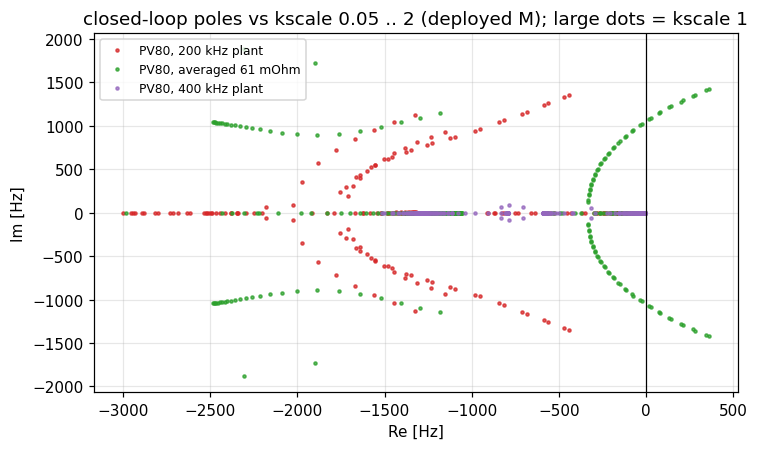

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for lab, p, col in (('PV80, 200 kHz plant', ns.pv80(R_w=0.29), 'tab:red'), ('PV80, averaged 61 mOhm', ns.pv80(), 'tab:green'), ('PV80, 400 kHz plant', ns.pv80(R_w=1.7), 'tab:purple')):
    for k in np.geomspace(0.05, 2.0, 25):
        cl = ns.ClosedLoop(p, M=M, kscale=k)
        z = np.linalg.eigvals(cl.A_cl()); s = np.log(z.astype(complex)) / cl.Ts
        s = s[(abs(s) > 1) & (abs(s) < 2 * math.pi * 3000)]
        ax.plot(s.real / (2 * math.pi), s.imag / (2 * math.pi), '.', color=col, ms=4 + 6 * (abs(k - 1) < 0.05), alpha=0.75, label=lab if k == 0.05 else None)
ax.axvline(0, color='k', lw=0.8); ax.set_xlabel('Re [Hz]'); ax.set_ylabel('Im [Hz]'); ax.set_title('closed-loop poles vs kscale 0.05 .. 2 (deployed M); large dots = kscale 1'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10 · How far off, the expressions to keep, open items

| quantity | 2026 analysis (App. B, notebooks) | this derivation | measured / identified |
|---|---|---|---|
| structure of $G$ | $u_d \to$ circulating, $u_c \to v_d$ with the injected current slaved through $g$ (correct, mislabelled in the retrospective) | same, for every $N$: $G_v = -\bar V$ diagonal + $O(R_m g)$, $G_c = \bar V/R$ diagonal | as derived (2-module 2026, S9i/S10i, Simulink) |
| $u_c \to v_d$ | −77 (2 modules) | $-\bar V$: −41 PV80, −46.5 bench QSPICE | −37 … −47 |
| $u_d \to i_c$ | $-\bar V/R$, $R$ = copper (41 800) | $\bar V/(R_w + 64 C_p f^3 (L+M)^2)$: 206 / 63 / 27 at 200 / 300 / 400 kHz | 142 / 58 / 23 (QSPICE), 742 (Simulink, 61 mΩ) |
| equilibrium | $D/(1-D) = V_{C2}/V_{C1}$, $\bar I = I_{pv2}/2(1-D)$ with a load across module 1 | $D_j/(1-D_j) = v_{j+1}/v_j$; $T I_m = \Delta I$; $I_{str} = \overline{I}$ | QSPICE S10i: $I_m$ within 1 %, $I_{str}$ within 1 % |
| winding modes | sum mode $L+M$, circulating $L-M$ | circulating $L+M$ (ripple 8.4 A pp at 200 kHz), sum $L-M$ | QSPICE ripple 8.4 / 4.1 A pp at 200 / 400 kHz |
| voltage-mode resonance | 5.6 kHz, $\zeta$ 0.003 (copper) | 7-9 kHz at $N=3$: $\zeta$ 0.3 with 61 mΩ, over-damped with $R_{sw}$ | 6.3 kHz, $\zeta$ 0.53 (June 2026 Simulink, 2 modules; open) |
| controllability | $\bar I \ne 0$, $V_\Sigma \ne 0$, duty unsaturated | $\bar V_j \ne 0$, duty unsaturated; string-sum mode uncontrollable and unobservable (belongs to load / MPPT) | decentralised control failed on the shared nodes (3.1): the dynamic coupling, now in the model |
| closed-loop $\tau$ at kscale 1 | — | 1.1 ms (vd), 0.3 ms (ic) | QSPICE 0.77, Simulink 0.56 ms (`8_Results/analysis/REPORT.md`) |

**Expressions to keep**

$$(L-M)\,\dot i_m = \bar V u_c + v_d - R\,i_m,\qquad (L+M)\,\dot i_c = \bar V u_d - R\,i_c,\qquad C_n\dot\phi = -G_n\phi + S i_m + w$$
$$\frac{D_j}{1-D_j} = \frac{v_{j+1}}{v_j},\qquad T(N)\,I_m = \Delta I,\quad T^{-1}_{jk} = \tfrac{2}{N}\min(j,k)(N-\max(j,k)),\qquad I_{str} = \tfrac1N\textstyle\sum_k I_k$$
$$G(N) = \begin{bmatrix}-(R I + Z_e)^{-1} Z_e\,\mathrm{diag}\bar V & 0\\ 0 & \mathrm{diag}\bar V / R\end{bmatrix},\qquad
R = R_w + 64\,C_p f_{sw}^3 (L+M)^2,\qquad \Delta i_c = \frac{\bar V}{2 f_{sw}(L+M)}$$

**Open items**
* The June 2026 two-module resonance (6.34 kHz, $\zeta$ 0.53) is not reproduced by either inductor assignment with
  $C_e = C$; it needs that Simulink model's inductor wiring and capacitor values to be re-read.
* $C_p$ was taken as a constant 2.2 nF; the device model's $C_{oss}$ is voltage dependent, so $R_{sw}$ at other string
  voltages should be re-measured (one open-loop $u_d$ step at 0.0025 per operating point, `qspice_ud_sweep.py`).
* The $u_d \to v_d$ cross term of the switching plant (−10 … −25 V/unit) is second order in the present model.
* Dead time at 400 kHz is at the ZVS boundary ($\tau_e \approx t_d$): the characteristic beyond $u_d \approx 0.02$ is hard-switched
  and the linear model stops there; the firmware clamps and the kscale ≤ 0.3 used on hardware stay inside it.